# 07 · Physics-driven encoding: One Particle – One Qubit (1P1Q)

**Encoding** (Bal et al., PRD 112, 076004, Eqs. 1–3): each of the $N$ hardest jet constituents gets one qubit,

$$\theta_i = f\,\frac{p_{T,i}}{p_{T,\mathrm{jet}}}\,\Delta\eta_i, \qquad \varphi_i = f\,\frac{p_{T,i}}{p_{T,\mathrm{jet}}}\,\Delta\phi_i, \qquad |\psi_i\rangle = R_X(\varphi_i)\,R_Y(\theta_i)\,|0\rangle ,$$

with $\Delta\eta, \Delta\phi$ measured from the jet axis. All inputs are **dimensionless and relative to the jet**, so there is no global normalisation, no unit dependence and no sign ambiguity across features.

**Differences from the paper:** the paper trains $f$ inside a VQC (it converged to 7.27). Here the model is the same fixed QSVC as in notebook 05, and $f$ is scanned over {1, π, 7.27} (the paper's range is [1, 2π+1]) and, **outside that range**, {20, 50}: it acts as the kernel bandwidth. The pT fractions and Δη, Δφ are small numbers, so at the paper's $f$ the rotation angles are small and all jets stay close to $|0\cdots0\rangle$; larger $f$ tests whether widening the angles helps. Jets with fewer than $N$ constituents are padded with qubits left in $|0\rangle$.

**Grid:** $N \in \{4, 10\}$ × $f \in \{1, \pi, 7.27, 20, 50\}$, the same 5 balanced 400-jet subsamples and test set as notebook 05, exact kernels and 1000 shots.
Then a shot scan for the best configuration, and the combined figures with notebooks 05–06.

In [1]:
import sys
sys.path.insert(0, "src")

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score
from sklearn.svm import SVC

from jet_data import (load_jets, select_quark_gluon, event_level_split, balanced_subsample,
                      leading_constituents, BOOKKEEPING, PF_KEYS)
from kernels import onep1q_states, onep1q_kernel, shot_noise, concentration, effective_rank
from figure_style import set_style, save, COLORS

set_style()
SEED = 42
SEEDS = [0, 1, 2, 3, 4]
N_PER_CLASS = 200
SHOTS = 1000
SHOT_GRID = [3, 10, 30, 100, 300, 1000, 3000, 10000]
N_GRID = [4, 10]
F_GRID = [1.0, np.pi, 7.27, 20.0, 50.0]      # 20 and 50 lie outside the paper's range [1, 2π+1]
RESULTS = Path("results")

raw = load_jets(features=("jetPt", "jetEta", "jetPhi"), extra=BOOKKEEPING + PF_KEYS)
jets = select_quark_gluon(raw, require_loose_id=True)       # same selection and order as notebooks 02-05
y = jets["label"]
train, test = event_level_split(jets, test_fraction=0.3, seed=SEED)
z, d_eta, d_phi, n_const = leading_constituents(jets, n_max=max(N_GRID))
print(f"train {int(train.sum())}, test {int(test.sum())}")

train 9729, test 4183


## 1. Sanity checks on the constituents

- `PF_dEta`, `PF_dPhi` should be relative to the jet axis: their pT-weighted mean per jet should be close to 0.
- The pT fractions of all constituents should sum to roughly 1.
- How many jets have fewer than N constituents (padding)?

In [2]:
z_all, de_all, dp_all, _ = leading_constituents(jets, n_max=200)        # effectively all constituents
w_mean_eta = np.sum(z_all * de_all, axis=1) / np.sum(z_all, axis=1)
w_mean_phi = np.sum(z_all * dp_all, axis=1) / np.sum(z_all, axis=1)
print(f"median |pT-weighted mean d_eta| = {np.median(np.abs(w_mean_eta)):.4f}")
print(f"median |pT-weighted mean d_phi| = {np.median(np.abs(w_mean_phi)):.4f}")
print(f"median sum of pT fractions      = {np.median(z_all.sum(axis=1)):.3f}")
print(f"constituents per jet: median {np.median(n_const):.0f}, 5% {np.percentile(n_const, 5):.0f}, 95% {np.percentile(n_const, 95):.0f}")
for n in N_GRID:
    print(f"fraction of jets with fewer than {n} constituents: {np.mean(n_const < n):.3f}")
for f in F_GRID:
    theta = f * z[:, :4] * d_eta[:, :4]
    print(f"f = {f:5.2f}: |theta| of the 4 hardest constituents, median {np.median(np.abs(theta)):.3f} rad, 95% {np.percentile(np.abs(theta), 95):.3f} rad")

median |pT-weighted mean d_eta| = 0.0036
median |pT-weighted mean d_phi| = 0.0001
median sum of pT fractions      = 0.940
constituents per jet: median 33, 5% 15, 95% 65
fraction of jets with fewer than 4 constituents: 0.000
fraction of jets with fewer than 10 constituents: 0.005
f =  1.00: |theta| of the 4 hardest constituents, median 0.002 rad, 95% 0.014 rad
f =  3.14: |theta| of the 4 hardest constituents, median 0.007 rad, 95% 0.045 rad
f =  7.27: |theta| of the 4 hardest constituents, median 0.017 rad, 95% 0.103 rad
f = 20.00: |theta| of the 4 hardest constituents, median 0.047 rad, 95% 0.284 rad
f = 50.00: |theta| of the 4 hardest constituents, median 0.119 rad, 95% 0.711 rad


## 2. Cross-check against Qiskit circuits

In [3]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

n_chk, f_chk = 4, 7.27
jets_chk = np.flatnonzero(train)[:4]
psi = []
for j in jets_chk:
    qc = QuantumCircuit(n_chk)
    for i in range(n_chk):
        qc.ry(f_chk * z[j, i] * d_eta[j, i], i)
        qc.rx(f_chk * z[j, i] * d_phi[j, i], i)
    psi.append(Statevector(qc).data)
K_qiskit = np.array([[abs(np.vdot(a, b))**2 for b in psi] for a in psi])
S = onep1q_states(z[jets_chk, :n_chk], d_eta[jets_chk, :n_chk], d_phi[jets_chk, :n_chk], f_chk)
print(f"1P1Q max |Qiskit - closed form| = {np.max(np.abs(K_qiskit - onep1q_kernel(S, S))):.1e}")

1P1Q max |Qiskit - closed form| = 8.9e-16


## 3. Kernel experiment (same protocol as notebook 05)

In [4]:
def states(rows, n, f):
    return onep1q_states(z[rows, :n], d_eta[rows, :n], d_phi[rows, :n], f)

records = []
for n in N_GRID:
    for f in F_GRID:
        for s in SEEDS:
            idx = balanced_subsample(y, train, N_PER_CLASS, seed=s)
            SA, ST = states(idx, n, f), states(np.flatnonzero(test), n, f)
            K_tr, K_te = onep1q_kernel(SA, SA), onep1q_kernel(ST, SA)
            mean_k, var_k = concentration(K_tr)
            rec = {"n_qubits": n, "f": f, "seed": s, "kernel_mean": float(mean_k),
                   "kernel_var": float(var_k), "eff_rank": effective_rank(K_tr)}
            svc = SVC(kernel="precomputed", C=1.0).fit(K_tr, y[idx])
            rec["auc_exact"] = roc_auc_score(y[test], svc.decision_function(K_te))
            rng = np.random.default_rng(1000 + s)
            svc = SVC(kernel="precomputed", C=1.0).fit(shot_noise(K_tr, SHOTS, rng, symmetric=True), y[idx])
            rec["auc_shots"] = roc_auc_score(y[test], svc.decision_function(shot_noise(K_te, SHOTS, rng)))
            records.append(rec)
        print(f"N = {n:2d}, f = {f:5.2f} done")

def summarise(n, f, key):
    v = np.array([r[key] for r in records if r["n_qubits"] == n and r["f"] == f])
    return v.mean(), v.std()

print()
print(f"{'N':>3s} {'f':>6s} {'K mean':>8s} {'K var':>10s} {'eff. rank':>9s} {'AUC exact':>14s} {'AUC 1000 shots':>15s}")
for n in N_GRID:
    for f in F_GRID:
        km, _ = summarise(n, f, "kernel_mean"); kv, _ = summarise(n, f, "kernel_var"); er, _ = summarise(n, f, "eff_rank")
        ae, ae_s = summarise(n, f, "auc_exact"); ash, ash_s = summarise(n, f, "auc_shots")
        print(f"{n:3d} {f:6.2f} {km:8.4f} {kv:10.2e} {er:9.2f} {ae:8.3f} ± {ae_s:.3f} {ash:9.3f} ± {ash_s:.3f}")

N =  4, f =  1.00 done
N =  4, f =  3.14 done
N =  4, f =  7.27 done
N =  4, f = 20.00 done
N =  4, f = 50.00 done
N = 10, f =  1.00 done
N = 10, f =  3.14 done
N = 10, f =  7.27 done
N = 10, f = 20.00 done
N = 10, f = 50.00 done

  N      f   K mean      K var eff. rank      AUC exact  AUC 1000 shots
  4   1.00   0.9998   4.50e-08      1.00    0.500 ± 0.011     0.500 ± 0.009
  4   3.14   0.9983   4.34e-06      1.02    0.501 ± 0.011     0.500 ± 0.009
  4   7.27   0.9910   1.19e-04      1.07    0.504 ± 0.010     0.503 ± 0.010
  4  20.00   0.9369   4.92e-03      1.44    0.542 ± 0.021     0.536 ± 0.018
  4  50.00   0.7177   5.09e-02      3.69    0.623 ± 0.023     0.606 ± 0.019
 10   1.00   0.9998   6.35e-08      1.00    0.503 ± 0.008     0.503 ± 0.007
 10   3.14   0.9976   6.12e-06      1.02    0.505 ± 0.008     0.496 ± 0.005
 10   7.27   0.9873   1.67e-04      1.11    0.514 ± 0.007     0.515 ± 0.010
 10  20.00   0.9115   6.65e-03      1.73    0.594 ± 0.026     0.576 ± 0.021
 10  50.00   

## 4. Shot scan for the best 1P1Q configuration

In [5]:
best_n, best_f = max(((n, f) for n in N_GRID for f in F_GRID), key=lambda nf: summarise(*nf, "auc_exact")[0])
print(f"best configuration: N = {best_n}, f = {best_f:.2f}")
scan = {n: [] for n in SHOT_GRID}; scan["exact"] = []; n_star = []
for s in SEEDS:
    idx = balanced_subsample(y, train, N_PER_CLASS, seed=s)
    SA, ST = states(idx, best_n, best_f), states(np.flatnonzero(test), best_n, best_f)
    K_tr, K_te = onep1q_kernel(SA, SA), onep1q_kernel(ST, SA)
    off = K_tr[~np.eye(len(idx), dtype=bool)]
    n_star.append(np.mean(off * (1 - off)) / off.var())
    scan["exact"].append(roc_auc_score(y[test], SVC(kernel="precomputed").fit(K_tr, y[idx]).decision_function(K_te)))
    rng = np.random.default_rng(2000 + s)
    for n in SHOT_GRID:
        svc = SVC(kernel="precomputed").fit(shot_noise(K_tr, n, rng, symmetric=True), y[idx])
        scan[n].append(roc_auc_score(y[test], svc.decision_function(shot_noise(K_te, n, rng))))
print(f"N* ≈ {np.mean(n_star):.1f}; " + ", ".join(f"{n}: {np.mean(scan[n]):.3f}" for n in SHOT_GRID) + f"; exact {np.mean(scan['exact']):.3f}")

json.dump({"records": records, "best": {"n_qubits": best_n, "f": best_f, "n_star": float(np.mean(n_star)),
           "scan": {str(k): v for k, v in scan.items()}}}, open(RESULTS / "onep1q.json", "w"), indent=2)
print("saved results/onep1q.json")

best configuration: N = 10, f = 50.00
N* ≈ 3.1; 3: 0.536, 10: 0.548, 30: 0.575, 100: 0.593, 300: 0.619, 1000: 0.642, 3000: 0.653, 10000: 0.657; exact 0.660
saved results/onep1q.json


## 5. Combined main figure: all encodings

saved figures/fig09_all_encodings.pdf and .png


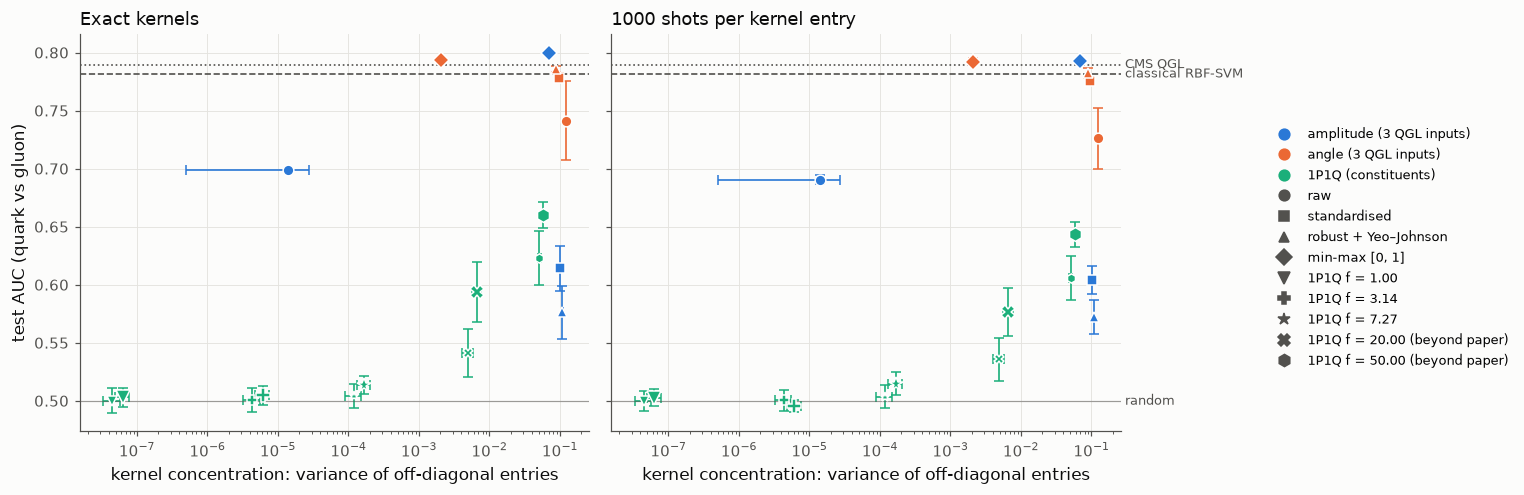

In [6]:
k05 = json.load(open(RESULTS / "kernel_experiment.json"))["records"]
baselines = json.load(open(RESULTS / "baselines.json"))
rbf = np.mean(baselines["rbf_svm_sub_auc"])

def summ05(enc, prep, key):
    v = np.array([r[key] for r in k05 if r["encoding"] == enc and r["prep"] == prep]); return v.mean(), v.std()

MARKERS = {"raw": "o", "standard": "s", "robust_yj": "^", "minmax": "D"}
PREP_LABEL = {"raw": "raw", "standard": "standardised", "robust_yj": "robust + Yeo–Johnson", "minmax": "min-max [0, 1]"}
ENC_COLOR = {"amplitude": COLORS["series1"], "angle": COLORS["series2"], "1P1Q": COLORS["series3"]}
F_MARKER = {1.0: "v", np.pi: "P", 7.27: "*", 20.0: "X", 50.0: "h"}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
for ax, key, title in ((axes[0], "auc_exact", "Exact kernels"), (axes[1], "auc_shots", f"{SHOTS} shots per kernel entry")):
    for enc in ("amplitude", "angle"):
        for prep in MARKERS:
            kv, kv_s = summ05(enc, prep, "kernel_var"); a, a_s = summ05(enc, prep, key)
            ax.errorbar(max(kv, 1e-12), a, xerr=kv_s, yerr=a_s, fmt=MARKERS[prep], color=ENC_COLOR[enc], markersize=7,
                        markeredgecolor="white", markeredgewidth=1, capsize=3, linewidth=1.1)
    for n in N_GRID:
        for f in F_GRID:
            kv, kv_s = summarise(n, f, "kernel_var"); a, a_s = summarise(n, f, key)
            ax.errorbar(max(kv, 1e-12), a, xerr=kv_s, yerr=a_s, fmt=F_MARKER[f], color=ENC_COLOR["1P1Q"],
                        markersize=9 if n == 10 else 6, markeredgecolor="white", markeredgewidth=1, capsize=3, linewidth=1.1)
    ax.axhline(rbf, color=COLORS["reference"], linestyle="--", linewidth=1.1)
    ax.axhline(baselines["qgl_test_auc"], color=COLORS["reference"], linestyle=":", linewidth=1.1)
    ax.axhline(0.5, color=COLORS["reference"], linewidth=0.8, alpha=0.5)
    ax.set_xscale("log"); ax.set_xlabel("kernel concentration: variance of off-diagonal entries")
    ax.set_title(title, loc="left")
axes[0].set_ylabel("test AUC (quark vs gluon)")
xr = axes[1].get_xlim()[1]
for yv, lab in ((rbf, " classical RBF-SVM"), (baselines["qgl_test_auc"], " CMS QGL"), (0.5, " random")):
    axes[1].text(xr, yv, lab, va="center", ha="left", fontsize=8.5, color=COLORS["reference"])
handles = [Line2D([], [], color=ENC_COLOR[e], marker="o", linestyle="", markersize=7, label=lab)
           for e, lab in (("amplitude", "amplitude (3 QGL inputs)"), ("angle", "angle (3 QGL inputs)"), ("1P1Q", "1P1Q (constituents)"))]
handles += [Line2D([], [], color=COLORS["reference"], marker=MARKERS[p], linestyle="", markersize=7, label=PREP_LABEL[p]) for p in MARKERS]
handles += [Line2D([], [], color=COLORS["reference"], marker=F_MARKER[f], linestyle="", markersize=8, label=f"1P1Q f = {f:.2f}" + (" (beyond paper)" if f > 7.3 else "")) for f in F_GRID]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8.5)
fig.tight_layout()
save(fig, "fig09_all_encodings")
plt.show()

## 6. Combined shot-budget figure

saved figures/fig10_shot_budget_all.pdf and .png


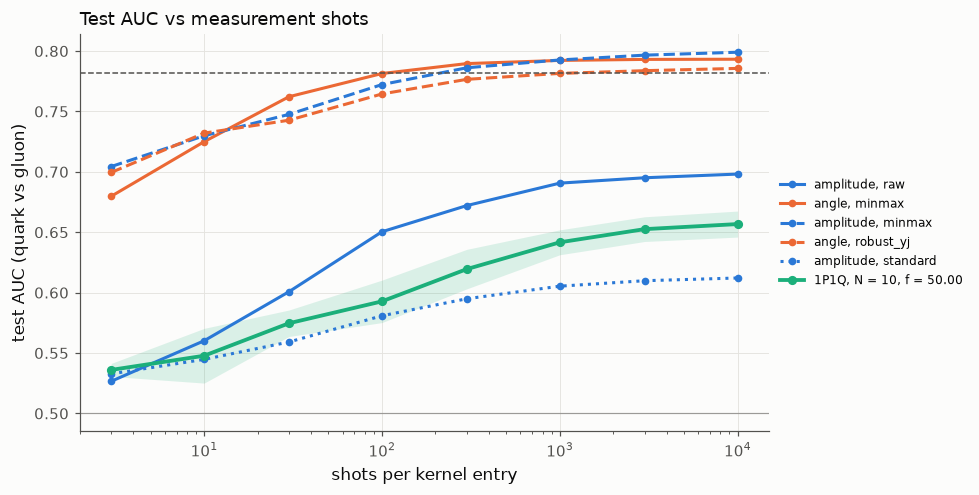

In [7]:
sb = json.load(open(RESULTS / "shot_budget.json"))
STYLE = {"amplitude/raw": "-", "angle/minmax": "-", "amplitude/minmax": "--", "angle/robust_yj": "--", "amplitude/standard": ":"}
fig, ax = plt.subplots(figsize=(9, 4.6))
for name, r in sb.items():
    enc = name.split("/")[0]
    mean = [np.mean(r["auc"][str(n)]) for n in SHOT_GRID]
    ax.plot(SHOT_GRID, mean, STYLE.get(name, "-"), color=ENC_COLOR[enc], marker="o", markersize=4, label=name.replace("/", ", "))
mean = np.array([np.mean(scan[n]) for n in SHOT_GRID]); std = np.array([np.std(scan[n]) for n in SHOT_GRID])
ax.plot(SHOT_GRID, mean, "-", color=ENC_COLOR["1P1Q"], marker="o", markersize=5, linewidth=2.5,
        label=f"1P1Q, N = {best_n}, f = {best_f:.2f}")
ax.fill_between(SHOT_GRID, mean - std, mean + std, color=ENC_COLOR["1P1Q"], alpha=0.15, linewidth=0)
ax.axhline(rbf, color=COLORS["reference"], linestyle="--", linewidth=1)
ax.axhline(0.5, color=COLORS["reference"], linewidth=0.8, alpha=0.5)
ax.set_xscale("log"); ax.set_xlabel("shots per kernel entry"); ax.set_ylabel("test AUC (quark vs gluon)")
ax.set_title("Test AUC vs measurement shots", loc="left")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()
save(fig, "fig10_shot_budget_all")
plt.show()

## 7. Summary for the research log

In [8]:
print(f"- 1P1Q (Bal et al.), fixed f, QSVC, same subsamples/test as nb 05; {SHOTS} shots")
for n in N_GRID:
    for f in F_GRID:
        kv, _ = summarise(n, f, "kernel_var"); ae, ae_s = summarise(n, f, "auc_exact"); ash, ash_s = summarise(n, f, "auc_shots")
        print(f"  - N={n}, f={f:.2f}: K var {kv:.2e}; AUC exact {ae:.3f} ± {ae_s:.3f}; AUC shots {ash:.3f} ± {ash_s:.3f}")
print(f"  - best N={best_n}, f={best_f:.2f}: AUC at 10 / 100 / 1000 shots {np.mean(scan[10]):.3f} / {np.mean(scan[100]):.3f} / {np.mean(scan[1000]):.3f}")

- 1P1Q (Bal et al.), fixed f, QSVC, same subsamples/test as nb 05; 1000 shots
  - N=4, f=1.00: K var 4.50e-08; AUC exact 0.500 ± 0.011; AUC shots 0.500 ± 0.009
  - N=4, f=3.14: K var 4.34e-06; AUC exact 0.501 ± 0.011; AUC shots 0.500 ± 0.009
  - N=4, f=7.27: K var 1.19e-04; AUC exact 0.504 ± 0.010; AUC shots 0.503 ± 0.010
  - N=4, f=20.00: K var 4.92e-03; AUC exact 0.542 ± 0.021; AUC shots 0.536 ± 0.018
  - N=4, f=50.00: K var 5.09e-02; AUC exact 0.623 ± 0.023; AUC shots 0.606 ± 0.019
  - N=10, f=1.00: K var 6.35e-08; AUC exact 0.503 ± 0.008; AUC shots 0.503 ± 0.007
  - N=10, f=3.14: K var 6.12e-06; AUC exact 0.505 ± 0.008; AUC shots 0.496 ± 0.005
  - N=10, f=7.27: K var 1.67e-04; AUC exact 0.514 ± 0.007; AUC shots 0.515 ± 0.010
  - N=10, f=20.00: K var 6.65e-03; AUC exact 0.594 ± 0.026; AUC shots 0.576 ± 0.021
  - N=10, f=50.00: K var 5.80e-02; AUC exact 0.660 ± 0.011; AUC shots 0.643 ± 0.011
  - best N=10, f=50.00: AUC at 10 / 100 / 1000 shots 0.548 / 0.593 / 0.642
